# TFID Vectorization

## Libraries Import

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
import numpy as np


## Load Data

In [2]:
# Load the saved TF-IDF vectorized dataset (with labels)
df = pd.read_csv("../../data/complete2_dataset.csv")

# Show first few rows (to verify)
print(df.head())
print(df.columns)

                                              review language     label
0                                           terrible       en  negative
1                  less movie show total money worst       en  negative
2  inapt brightness cannot brought zero even phon...       en  negative
3  able login account tried uninstalling reinstat...       en  negative
4  netflix one favourite platform watch show prob...       en  negative
Index(['review', 'language', 'label'], dtype='object')


## Separate Features and Labels

In [3]:
# Prepare text and labels
texts = df['review'].astype(str)
labels = df['label']

## Vectorization

In [4]:
# Convert text to TF-IDF features
vectorizer = TfidfVectorizer(max_features=10000)
X = vectorizer.fit_transform(texts)
y = labels.values

In [5]:
# Save TF-IDF features and labels together as a .npz file in the models folder
import numpy as np
from scipy import sparse

sparse.save_npz('../../models/tfidf_features_nb.npz', X)
np.save('../../models/labels_nb.npy', y)

# To load later:
# X_loaded = sparse.load_npz('../models/tfidf_features_nb.npz')
# y_loaded = np.load('../models/labels_nb.npy')

## Multinominal Model

### Initializing Model

In [6]:
# Initialize MultinomialNB model (supports predict_proba by default)
model = MultinomialNB() # Initialize the model

### Train/Test

In [7]:
# Split dataset into Training & Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [8]:
model.fit(X_train, y_train) # Train the model with training data

,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


### Kfold

In [9]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
print("Cross-validated accuracy scores:", scores)
print("Mean Accuracy:", scores.mean())

Cross-validated accuracy scores: [0.89073741 0.88239262 0.89183719 0.89453564 0.89588487]
Mean Accuracy: 0.8910775472268913


### Evaluating Model

In [10]:
# Predict and Evaluate Model
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8899082568807339
              precision    recall  f1-score   support

    negative       0.86      0.91      0.88      1856
     neutral       0.97      0.87      0.92      1887
    positive       0.85      0.89      0.87      1816

    accuracy                           0.89      5559
   macro avg       0.89      0.89      0.89      5559
weighted avg       0.89      0.89      0.89      5559



### Confusion Matrix

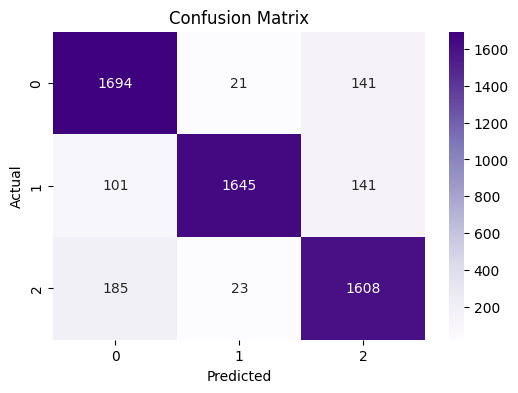

In [11]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Logistic Regression Model

### Initializing Model

In [12]:
model = LogisticRegression(max_iter=1000)  # Initialize the model

### Train/Test

In [13]:
# Split dataset into Training & Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

In [14]:
# Train the model with training data
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Kfold

In [15]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
print("Cross-Validation Accuracy Scores:", scores)
print("Mean Accuracy:", scores.mean())

Cross-Validation Accuracy Scores: [0.90310252 0.89880819 0.90195638 0.89903306 0.91364965]
Mean Accuracy: 0.9033099571613228


### Evaluating Model

In [16]:
# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9016010073754273

Classification Report:
               precision    recall  f1-score   support

    negative       0.85      0.95      0.90      1856
     neutral       0.98      0.84      0.91      1887
    positive       0.89      0.91      0.90      1816

    accuracy                           0.90      5559
   macro avg       0.91      0.90      0.90      5559
weighted avg       0.91      0.90      0.90      5559



### Confusion Matrix

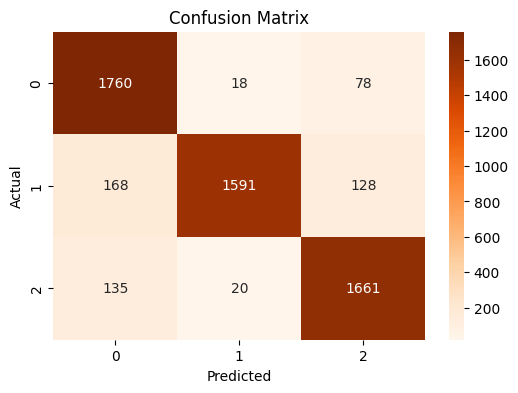

In [17]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## SVC Model

### Initializing Model

In [18]:
model = SVC(kernel='linear', probability=True)  # Initialize the model with linear kernel and probability support

### Train/Test

In [19]:
# Split dataset into Training & Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [20]:
# Train the model with training data
model.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


### Kfold

In [21]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
print("Cross-Validation Accuracy Scores:", scores)
print("Mean Accuracy:", scores.mean())

Cross-Validation Accuracy Scores: [0.90692446 0.90195638 0.90600405 0.90128176 0.91454913]
Mean Accuracy: 0.9061431560845319


### Evaluating Model

In [22]:
# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.901241230437129

Classification Report:
               precision    recall  f1-score   support

    negative       0.85      0.95      0.90      1856
     neutral       0.98      0.85      0.91      1887
    positive       0.89      0.91      0.90      1816

    accuracy                           0.90      5559
   macro avg       0.91      0.90      0.90      5559
weighted avg       0.91      0.90      0.90      5559



### Confusion Matrix

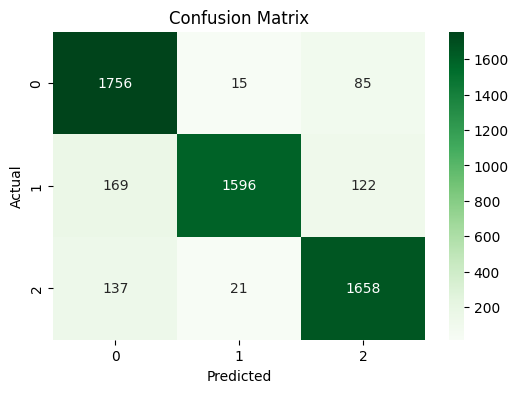

In [23]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## SGD Classifier

### Initializing Model

In [24]:
model = SGDClassifier(random_state=42)  # Initialize the model

### Train/Test

In [25]:
# Split dataset into Training & Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [26]:
# Train the model with training data
model.fit(X_train, y_train)

,loss,'hinge'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


### Kfold

In [27]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy')
print("Cross-Validation Accuracy Scores:", scores)
print("Mean Accuracy:", scores.mean())

Cross-Validation Accuracy Scores: [0.90467626 0.89925793 0.90353047 0.90150663 0.91499888]
Mean Accuracy: 0.9047940329993708


### Evaluating Model

In [28]:
# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9035797805360677

Classification Report:
               precision    recall  f1-score   support

    negative       0.85      0.95      0.90      1856
     neutral       0.99      0.84      0.91      1887
    positive       0.88      0.92      0.90      1816

    accuracy                           0.90      5559
   macro avg       0.91      0.90      0.90      5559
weighted avg       0.91      0.90      0.90      5559



### Confusion Matrix

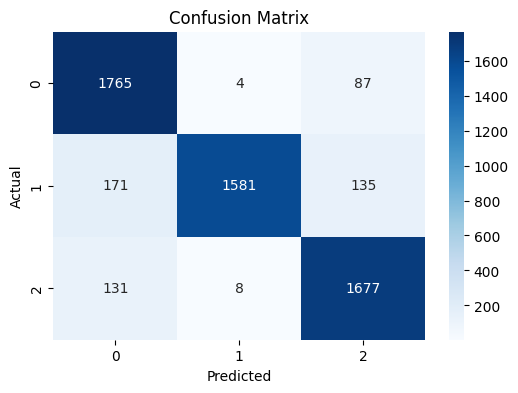

In [29]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## KNN Classifier

### Initializing Model

In [30]:
# Encode labels and setup hyperparameter search
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

param_dist = {
    'n_neighbors': np.arange(3, 21),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'cosine']
}

# Quick randomized search on sample data
print("Optimizing KNN hyperparameters...")
random_search = RandomizedSearchCV(
    KNeighborsClassifier(), param_dist, n_iter=15, cv=3, 
    scoring='accuracy', random_state=42, n_jobs=1, verbose=0
)

# Use sample for efficiency
sample_size = min(3000, X.shape[0])
sample_indices = np.random.choice(X.shape[0], sample_size, replace=False)
random_search.fit(X[sample_indices], y_encoded[sample_indices])

best_params = random_search.best_params_
best_score = random_search.best_score_
model = KNeighborsClassifier(**best_params)
knn_label_encoder = label_encoder

print(f"Best params: {best_params}")
print(f"CV score: {best_score:.4f}")

Optimizing KNN hyperparameters...
Best params: {'weights': 'distance', 'n_neighbors': np.int64(14), 'metric': 'cosine'}
CV score: 0.8243


### Parameter Search Results

In [31]:
# Display top 5 parameter combinations and their scores
results_df = pd.DataFrame(random_search.cv_results_)

# Filter out NaN scores and get valid results
valid_results = results_df[~results_df['mean_test_score'].isna()]
top_results = valid_results.nlargest(5, 'mean_test_score')[['params', 'mean_test_score', 'std_test_score']]

print("Top 5 parameter combinations:")
for idx, (_, row) in enumerate(top_results.iterrows(), 1):
    params = row['params']
    mean_score = row['mean_test_score']
    std_score = row['std_test_score']
    print(f"{idx}. {params}")
    print(f"   Mean CV Score: {mean_score:.4f} (+/- {std_score*2:.4f})")
    print()

print(f"Selected best parameters: {best_params}")
print(f"Best cross-validation score: {best_score:.4f}")

print(f"\nOptimization Results Summary:")
print(f"- Best k value: {best_params['n_neighbors']}")
print(f"- Best weighting: {best_params['weights']}")
print(f"- Best distance metric: {best_params['metric']}")
print(f"- Cross-validation accuracy: {best_score:.4f}")
print("\nNote: Final model comparison will be shown after training and testing in later cells.")

Top 5 parameter combinations:
1. {'weights': 'distance', 'n_neighbors': np.int64(14), 'metric': 'cosine'}
   Mean CV Score: 0.8243 (+/- 0.0159)

2. {'weights': 'distance', 'n_neighbors': np.int64(8), 'metric': 'cosine'}
   Mean CV Score: 0.8230 (+/- 0.0102)

3. {'weights': 'distance', 'n_neighbors': np.int64(7), 'metric': 'cosine'}
   Mean CV Score: 0.8217 (+/- 0.0189)

4. {'weights': 'distance', 'n_neighbors': np.int64(5), 'metric': 'cosine'}
   Mean CV Score: 0.8210 (+/- 0.0241)

5. {'weights': 'distance', 'n_neighbors': np.int64(6), 'metric': 'cosine'}
   Mean CV Score: 0.8197 (+/- 0.0222)

Selected best parameters: {'weights': 'distance', 'n_neighbors': np.int64(14), 'metric': 'cosine'}
Best cross-validation score: 0.8243

Optimization Results Summary:
- Best k value: 14
- Best weighting: distance
- Best distance metric: cosine
- Cross-validation accuracy: 0.8243

Note: Final model comparison will be shown after training and testing in later cells.


### Train/Test

In [32]:
# Split dataset into Training & Testing sets using encoded labels
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.25, random_state=42
)

print(f"Using optimized KNN with parameters: {best_params}")
print(f"Training set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
print(f"Training labels distribution: {np.bincount(y_train)}")
print(f"Test labels distribution: {np.bincount(y_test)}")

Using optimized KNN with parameters: {'weights': 'distance', 'n_neighbors': np.int64(14), 'metric': 'cosine'}
Training set size: 16677
Test set size: 5559
Training labels distribution: [5512 5613 5552]
Test labels distribution: [1856 1887 1816]


In [33]:
# Train the model with training data
model.fit(X_train, y_train)

,n_neighbors,np.int64(14)
,weights,'distance'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'cosine'
,metric_params,None
,n_jobs,None


### Kfold

In [34]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X, y_encoded, cv=kf, scoring='accuracy')  # Use encoded labels
print("Cross-Validation Accuracy Scores:", scores)
print("Mean Accuracy:", scores.mean())
print("Standard Deviation:", scores.std())

Cross-Validation Accuracy Scores: [0.89433453 0.89543512 0.90487969 0.89498538 0.89655948]
Mean Accuracy: 0.8972388426115415
Standard Deviation: 0.00388871811219349


### Evaluating Model

In [35]:
# Predict on test set (returns encoded labels)
y_pred_encoded = model.predict(X_test)

# Decode predictions back to original string labels
y_pred = knn_label_encoder.inverse_transform(y_pred_encoded)
y_test_decoded = knn_label_encoder.inverse_transform(y_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test_decoded, y_pred))
print("\nClassification Report:")
print(classification_report(y_test_decoded, y_pred))

# Show comparison of optimized vs default KNN
print(f"\nOptimized KNN Accuracy: {accuracy_score(y_test_decoded, y_pred):.4f}")
print(f"Improvement from hyperparameter optimization: {best_score:.4f} -> {accuracy_score(y_test_decoded, y_pred):.4f}")

Accuracy: 0.8801942795466811

Classification Report:
              precision    recall  f1-score   support

    negative       0.90      0.87      0.89      1856
     neutral       0.94      0.85      0.90      1887
    positive       0.81      0.92      0.86      1816

    accuracy                           0.88      5559
   macro avg       0.89      0.88      0.88      5559
weighted avg       0.89      0.88      0.88      5559


Optimized KNN Accuracy: 0.8802
Improvement from hyperparameter optimization: 0.8243 -> 0.8802


### Confusion Matrix

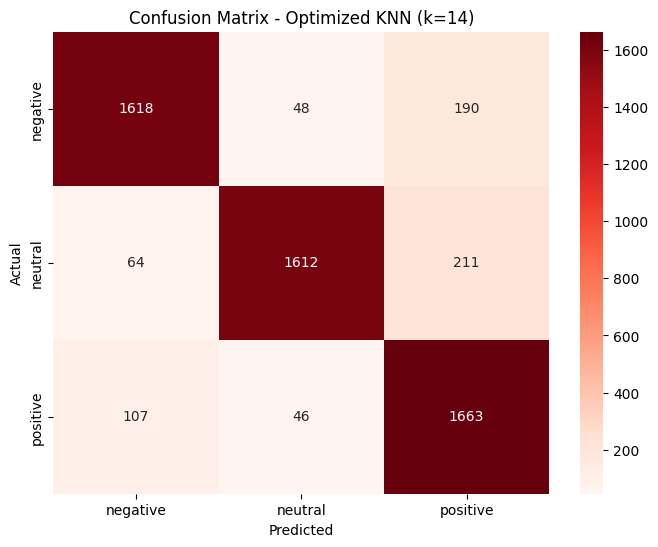

Optimized Parameters:
- k (n_neighbors): 14
- weights: distance
- metric: cosine
- Cross-validation score: 0.8243
- Test accuracy: 0.8802


In [36]:
cm = confusion_matrix(y_test_decoded, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=knn_label_encoder.classes_, 
            yticklabels=knn_label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - Optimized KNN (k={best_params["n_neighbors"]})')
plt.show()

# Print parameter summary
print(f"Optimized Parameters:")
print(f"- k (n_neighbors): {best_params['n_neighbors']}")
print(f"- weights: {best_params['weights']}")
print(f"- metric: {best_params['metric']}")
print(f"- Cross-validation score: {best_score:.4f}")
print(f"- Test accuracy: {accuracy_score(y_test_decoded, y_pred):.4f}")

## Stacking Classifier

### Initializing Model

In [37]:
# Define base estimators
base_estimators = [
    ('nb', MultinomialNB()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('svc', SVC(kernel='linear', probability=True, random_state=42)),
    ('sgd', SGDClassifier(random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=5))
]

# Initialize Stacking Classifier with Logistic Regression as meta-learner
# Set n_jobs=1 to avoid WRITEBACKIFCOPY error with sparse matrices
model = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(random_state=42),
    cv=3,
    n_jobs=1  # Changed from -1 to 1 to fix the sparse matrix error
)

### Train/Test

In [38]:
# Split dataset into Training & Testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [39]:
# Train the stacking model with training data
print("Training Stacking Classifier...")
model.fit(X_train, y_train)
print("Training completed!")

Training Stacking Classifier...
Training completed!


### Kfold

In [40]:
print("Running K-Fold Cross-Validation...")
kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)  # Using 3-fold for stacking to save time
scores = cross_val_score(model, X, y, cv=kf, scoring='accuracy', n_jobs=1)  # Changed n_jobs=-1 to n_jobs=1
print("Cross-Validation Accuracy Scores:", scores)
print("Mean Accuracy:", scores.mean())

Running K-Fold Cross-Validation...
Cross-Validation Accuracy Scores: [0.90704263 0.90623314 0.90582839]
Mean Accuracy: 0.906368051807879


### Evaluating Model

In [41]:
# Predict on test set
y_pred = model.predict(X_test)

# Evaluate performance
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9134736463392696

Classification Report:
               precision    recall  f1-score   support

    negative       0.90      0.93      0.92      1856
     neutral       0.96      0.89      0.92      1887
    positive       0.89      0.92      0.90      1816

    accuracy                           0.91      5559
   macro avg       0.91      0.91      0.91      5559
weighted avg       0.91      0.91      0.91      5559



### Confusion Matrix

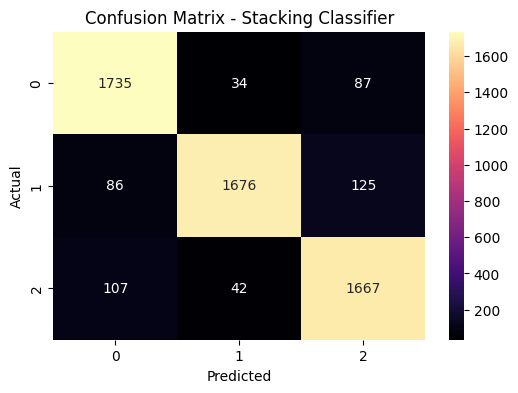

In [42]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma')  # Fixed: Changed 'Magma' to 'magma'
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Stacking Classifier')
plt.show()

## Export Files as .pkl

In [43]:
joblib.dump(model, '../../models/multinominalnb_model.pkl')  # Save the model in the models folder
joblib.dump(model, '../../models/logisticregression_model.pkl')  # Save the model in the models folder
joblib.dump(model, '../../models/svc_model.pkl')  # Save the model in the models folder
joblib.dump(model, '../../models/sgdclassifier_model.pkl')  # Save the SGD Classifier model
joblib.dump(model, '../../models/knn_model.pkl')  # Save the KNN model
joblib.dump(model, '../../models/stacking_model.pkl')  # Save the Stacking Classifier model
# Save the fitted vectorizer to disk
joblib.dump(vectorizer, '../../models/tfidf_vectorizer.pkl')

['../../models/tfidf_vectorizer.pkl']

# CountVectorization

## Load Dataset

In [44]:
import pandas as pd

# Load the dataset
df = pd.read_csv('../../data/complete2_dataset.csv')
print(df.head())
print(df.columns)

                                              review language     label
0                                           terrible       en  negative
1                  less movie show total money worst       en  negative
2  inapt brightness cannot brought zero even phon...       en  negative
3  able login account tried uninstalling reinstat...       en  negative
4  netflix one favourite platform watch show prob...       en  negative
Index(['review', 'language', 'label'], dtype='object')


## Count Vectorization with BoW

In [50]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
import sys
sys.path.append('../../app')

from preprocessing import mark_negation

# Apply negation handling only to English reviews
df['review'] = df['review'].fillna('').astype(str)

df.loc[df['language'] == 'en', 'review'] = df.loc[df['language'] == 'en', 'review'].apply(mark_negation)

# Vectorize (BoW)
vectorizer = CountVectorizer(token_pattern=r"[^ ]+")
X = vectorizer.fit_transform(df['review'].fillna(''))

# Label encoding
le = LabelEncoder()
y = le.fit_transform(df['label'])

print("X shape:", X.shape)
print("Unique labels:", list(le.classes_))

X shape: (22236, 18229)
Unique labels: ['negative', 'neutral', 'positive']


## XGBoost Training & Testing

In [51]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from xgboost import XGBClassifier

# Prepare data
X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

# One stratified split
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X, y))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Train model
model = XGBClassifier(use_label_encoder=False, eval_metric='mlogloss')
model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

/Users/s.n.h/.virtualenvs/my_env/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [13:49:36] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

    negative       0.88      0.94      0.91      1474
     neutral       0.99      0.85      0.91      1500
    positive       0.83      0.90      0.87      1474

    accuracy                           0.90      4448
   macro avg       0.90      0.90      0.90      4448
weighted avg       0.90      0.90      0.90      4448



## CatBoost Training & Testing

In [52]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from catboost import CatBoostClassifier

X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X, y))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

catboost_model = CatBoostClassifier(verbose=0)
catboost_model.fit(X_train, y_train)

y_pred = catboost_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.88      0.92      0.90      1474
     neutral       0.91      0.91      0.91      1500
    positive       0.89      0.86      0.87      1474

    accuracy                           0.89      4448
   macro avg       0.89      0.89      0.89      4448
weighted avg       0.89      0.89      0.89      4448



## GussianNB Training & Testing

In [53]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from sklearn.naive_bayes import GaussianNB

X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

X_dense = X.toarray()

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X_dense, y))

X_train, X_test = X_dense[train_idx], X_dense[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

y_pred = nb_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.82      0.68      0.75      1474
     neutral       0.60      0.94      0.74      1500
    positive       0.71      0.43      0.53      1474

    accuracy                           0.69      4448
   macro avg       0.71      0.68      0.67      4448
weighted avg       0.71      0.69      0.67      4448



## Decision Tree Training & Testing

In [54]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier

X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X, y))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.80      0.95      0.87      1474
     neutral       0.94      0.88      0.91      1500
    positive       0.90      0.79      0.84      1474

    accuracy                           0.87      4448
   macro avg       0.88      0.87      0.87      4448
weighted avg       0.88      0.87      0.87      4448



## Random Forest Training & Testing

In [55]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier

X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X, y))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

              precision    recall  f1-score   support

    negative       0.81      0.98      0.88      1474
     neutral       0.99      0.87      0.92      1500
    positive       0.92      0.84      0.88      1474

    accuracy                           0.90      4448
   macro avg       0.91      0.90      0.90      4448
weighted avg       0.91      0.90      0.90      4448



## LightGBM Training & Testing

In [56]:
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report
from lightgbm import LGBMClassifier

X = vectorizer.transform(df['review'].astype(str).fillna(''))
y = le.fit_transform(df['label'])

X = X.astype('float32')

sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(sss.split(X, y))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

lgbm_model = LGBMClassifier()
lgbm_model.fit(X_train, y_train)

y_pred = lgbm_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.060570 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3951
[LightGBM] [Info] Number of data points in the train set: 17788, number of used features: 1241
[LightGBM] [Info] Start training from score -1.104589
[LightGBM] [Info] Start training from score -1.086765
[LightGBM] [Info] Start training from score -1.104589
              precision    recall  f1-score   support

    negative       0.89      0.95      0.92      1474
     neutral       0.94      0.91      0.92      1500
    positive       0.90      0.87      0.89      1474

    accuracy                           0.91      4448
   macro avg       0.91      0.91      0.91      4448
weighted avg       0.91      0.91      0.91      4448



/Users/s.n.h/.virtualenvs/my_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


## Confusion Matrix

/Users/s.n.h/.virtualenvs/my_env/lib/python3.13/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


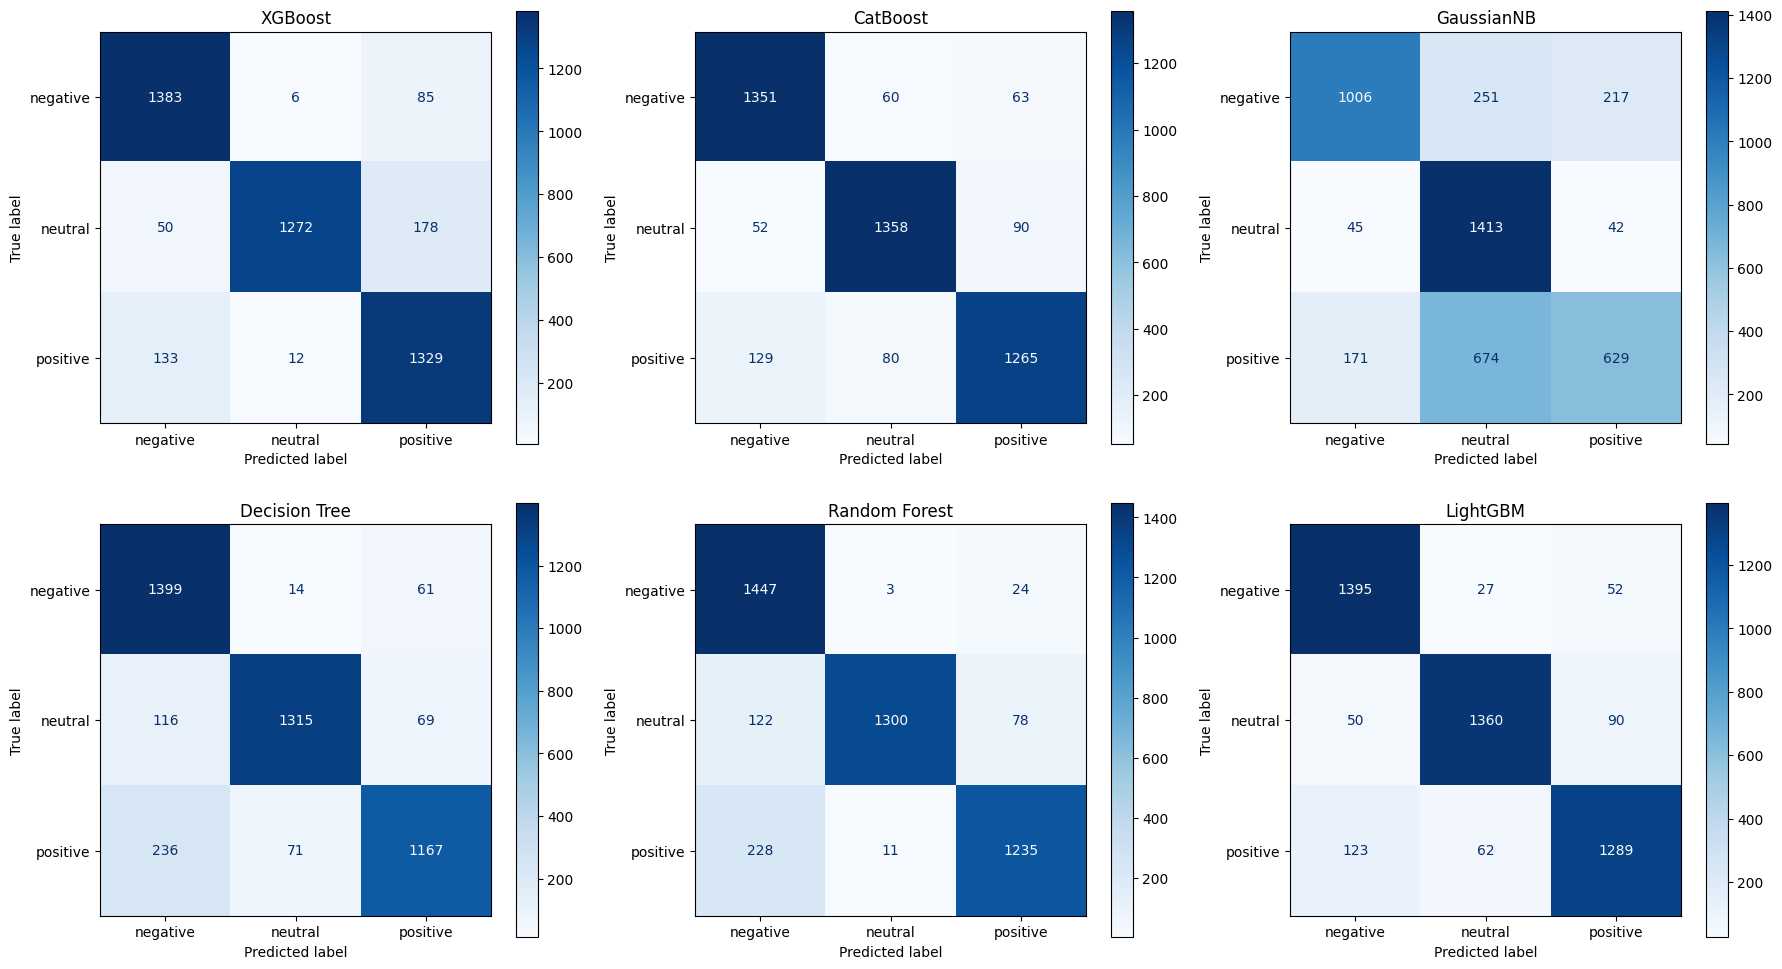

In [57]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt


nb_pred = nb_model.predict(X_test.toarray())

xgb_pred = model.predict(X_test)
catboost_pred = catboost_model.predict(X_test)
dt_pred = dt_model.predict(X_test)
rf_pred = rf_model.predict(X_test)
lgbm_pred = lgbm_model.predict(X_test)

# Create 2x3 grid
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Helper list
models = [
    ("XGBoost", xgb_pred),
    ("CatBoost", catboost_pred),
    ("GaussianNB", nb_pred),
    ("Decision Tree", dt_pred),
    ("Random Forest", rf_pred),
    ("LightGBM", lgbm_pred)
]

# Render each confusion matrix
for ax, (name, preds) in zip(axes.flat, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds, display_labels=le.classes_,
        cmap="Blues", ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

## Export Files as .pkl

In [58]:
import joblib

joblib.dump(model, "../../models/xgboost_model.pkl")
joblib.dump(catboost_model, "../../models/catboost_model.pkl")
joblib.dump(nb_model, "../../models/gaussian_nb_model.pkl")
joblib.dump(dt_model, "../../models/decision_tree_model.pkl")
joblib.dump(rf_model, "../../models/random_forest_model.pkl")
joblib.dump(lgbm_model, "../../models/lightgbm_model.pkl")

joblib.dump(vectorizer, "../../models/count_vectorizer.pkl")
joblib.dump(le, "../../models/label_encoder.pkl")

['../../models/label_encoder.pkl']